# IND320 Data to Decision - Compulsory work, part 3

Weather data from open-meteo (ERA5) for regions drawn from NVE's map data, outlier and anomaly
detection, and STL decomposition and spectrogram of the reservoir filling.

## Links

- **GitHub repository:** https://github.com/limmen20/limmen-streamlit-dashboard
- **Streamlit app:** https://limmen-app-dashboard.streamlit.app/

## Feedback from part 2

- *Filter the cross-border line chart by connection* (teacher): the Cross-border flows page now has a
  multiselect above the line chart, so you can show only the connections you are interested in.
- *The flows come from Energy-Charts, not the ENTSO-E API* (peer review): correct. I have not got an
  ENTSO-E security token yet, so the part 2 notebook used Energy-Charts, which republishes the same
  ENTSO-E data. The code switches to the ENTSO-E API by itself once a token is added to the secrets file.

## AI usage

I used an AI assistant (Claude) as a coding helper in this part. It helped me find the NVE map layers
behind atlas.nve.no, draft and comment the functions for sampling locations, downloading weather data,
SPC/DCT outliers, LOF anomalies, STL and the spectrogram, and add the two new pages to the Streamlit app.
The notebook was run from start to end and the app was tested locally before deployment.

## Log

Part 3 adds weather data and time series analysis to the project.

To get weather data for the same areas as the reservoir statistics, I needed the shapes of the areas.
In NVE Atlas the price areas (NO1-NO5) and NVE's regions (RØ, RS, RV, RM, RN) are available as map
layers. The layers are served by NVE's map server, so the notebook downloads them from there and saves
them as shapefiles in `data/shapefiles/`. The reservoir statistics use three watercourse regions, where
the east (VASS1) is RØ + RS, the west (VASS2) is RV, and the north (VASS3) is RM + RN. With geopandas
I built one polygon per area (NO, NO1-NO5 and VASS1-3) and sampled 1000 random locations inside each
of them. Sampling is done in UTM coordinates, so the points are spread evenly by area. The locations
are stored in MongoDB, so the Streamlit app can use them without the shapefiles.

The weather data comes from open-meteo's historical API with the ERA5 reanalysis model. I wrote a
function that takes a region and a time interval, looks up the region's locations and downloads hourly
precipitation, temperature and some other variables (rain, snowfall, humidity, wind, cloud cover and
pressure). The free API limits how much can be downloaded, so the function uses a random subset of the
locations, and the region average is used in the analysis. I tested it with NO3 for 2024.

For precipitation I used Statistical Process Control. A DCT high-pass filter removes the slow seasonal
part, and the limits are set from the median and the MAD of what is left, since those are not pulled
by the extreme values. Precipitation comes in short heavy bursts, so the share of outliers is higher
than for normally distributed data. For temperature I used the Local Outlier Factor on the deviation
from a 30-day moving average, so the anomalies are hours that are unusually warm or cold for the time
of year. With only 20 neighbours LOF also marked ordinary values lying in small gaps, so the default
is 100 neighbours.

For the reservoir filling I used STL to split the weekly series into trend, seasonal pattern and
residual, and a spectrogram to see how the frequency content changes over time. The yearly cycle
dominates, as expected for snow-fed hydropower.

In the Streamlit app there are two new pages with tabs: one for STL and the spectrogram and one for the
outlier and anomaly analysis. Both use the area chosen in the sidebar, which is shared with the other
reservoir pages, and the weather is downloaded in the background for that area and a chosen year. The
pages are now grouped in the sidebar (Reservoirs, Weather, Power exchange). Following the feedback from
part 2, the cross-border line chart can be filtered by connection.

## 1. Setup

In [1]:
# Libraries
import io
import tomllib
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import geopandas as gpd                      # shapefiles and maps
import matplotlib.pyplot as plt
from scipy.fft import dct, idct              # discrete cosine transform
from scipy.signal import spectrogram
from sklearn.neighbors import LocalOutlierFactor
from statsmodels.tsa.seasonal import STL
from pymongo import MongoClient

# The notebook is in notebooks/, so the project folder is one level up
ROOT = Path.cwd().parent

# Passwords are in .streamlit/secrets.toml (in .gitignore, so not on GitHub)
with open(ROOT / ".streamlit" / "secrets.toml", "rb") as f:
    secrets = tomllib.load(f)

# Plot style: light grid, no frame on top/right
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
LINE, LIMIT, OUTLIER = "#2a78d6", "#eb6834", "#e34948"   # same colours as in the app

## 2. Shapefiles from NVE

In [NVE Atlas](https://atlas.nve.no) the electricity price areas and NVE's regions are available as
map layers. The layers come from NVE's map server, so the same polygons are downloaded here with a
query to the server (as GeoJSON in WGS84 coordinates) and saved as shapefiles in `data/shapefiles/`.
If the shapefiles are already there, they are just read.

| Layer | Content |
|---|---|
| `Omradekonsesjoner/0` (ELSpottomraader) | Electricity price areas NO1-NO5 |
| `Administrasjon2/0` (NVE_Region) | NVE's regions RØ (east), RS (south), RV (west), RM (mid), RN (north) |

In [2]:
SHAPE_DIR = ROOT / "data" / "shapefiles"
NVE_LAYERS = {
    "elspot_areas": "https://gis3.nve.no/map/rest/services/Mapservices/Omradekonsesjoner/MapServer/0",
    "nve_regions": "https://gis3.nve.no/map/rest/services/Mapservices/Administrasjon2/MapServer/0",
}
KEEP_COLUMNS = {"elspot_areas": ["ElSpotOmr"], "nve_regions": ["REGION", "REGIONNAVN"]}


def get_shapefile(name: str) -> gpd.GeoDataFrame:
    """Read the shapefile, or download the layer from NVE first if it is missing."""
    path = SHAPE_DIR / f"{name}.shp"
    if not path.exists():
        params = {"where": "1=1", "outFields": "*", "outSR": 4326, "f": "geojson"}
        response = requests.get(f"{NVE_LAYERS[name]}/query", params=params, timeout=120)
        response.raise_for_status()
        layer = gpd.read_file(io.BytesIO(response.content))[KEEP_COLUMNS[name] + ["geometry"]]
        SHAPE_DIR.mkdir(parents=True, exist_ok=True)
        layer.to_file(path, encoding="utf-8")
    return gpd.read_file(path)


elspot = get_shapefile("elspot_areas").sort_values("ElSpotOmr")
nve_regions = get_shapefile("nve_regions").sort_values("REGION")
print(elspot.drop(columns="geometry"), "\n")
print(nve_regions.drop(columns="geometry"))

  ElSpotOmr
2       NO1
0       NO2
3       NO3
4       NO4
1       NO5 

  REGION         REGIONNAVN
1     RM  Region Midt-Norge
2     RN        Region Nord
4     RS         Region Sør
0     RV        Region Vest
3     RØ         Region Øst


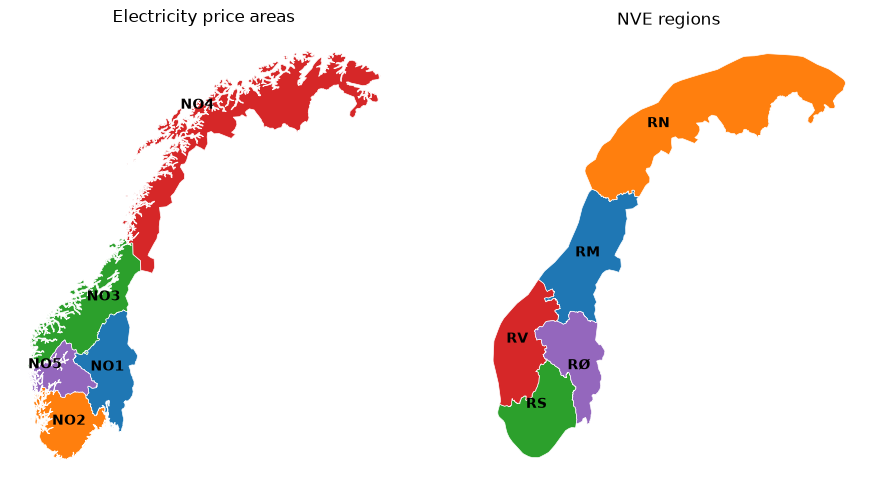

In [3]:
# The two layers side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 7))
for ax, layer, column, title in [(axes[0], elspot, "ElSpotOmr", "Electricity price areas"),
                                 (axes[1], nve_regions, "REGION", "NVE regions")]:
    layer.plot(ax=ax, column=column, cmap="tab10", edgecolor="white", linewidth=0.5)
    for _, row in layer.iterrows():   # label in the middle of each area
        point = row.geometry.representative_point()
        ax.annotate(row[column], (point.x, point.y), ha="center", fontsize=10, weight="bold")
    ax.set_title(title)
    ax.set_axis_off()
plt.show()

## 3. Regions and random locations

The regions follow the areas in the reservoir statistics (Magasinstatistikk):

| Region | Area in Magasinstatistikk | Made from |
|---|---|---|
| NO | Whole country | all price areas together |
| NO1-NO5 | Price areas (EL) | the price area polygon |
| VASS1 | Watercourse region 1 (east) | RØ + RS |
| VASS2 | Watercourse region 2 (west) | RV |
| VASS3 | Watercourse region 3 (north) | RM + RN |

1000 random locations are sampled inside each region. The sampling is done in UTM 33 (metres), so
the points are spread evenly by area, and the points are converted back to longitude/latitude.

In [4]:
# One polygon per region
geom_el = elspot.set_index("ElSpotOmr").geometry
geom_reg = nve_regions.set_index("REGION").geometry
regions = gpd.GeoDataFrame(
    {"region": ["NO", "NO1", "NO2", "NO3", "NO4", "NO5", "VASS1", "VASS2", "VASS3"],
     "geometry": [geom_el.union_all(), *[geom_el[f"NO{i}"] for i in range(1, 6)],
                  geom_reg[["RØ", "RS"]].union_all(), geom_reg["RV"], geom_reg[["RM", "RN"]].union_all()]},
    crs=4326,
)


def sample_locations(geometry, n: int = 1000, seed: int = 0) -> list[tuple[float, float]]:
    """n random (longitude, latitude) pairs inside a polygon, evenly spread by area."""
    points = (gpd.GeoSeries([geometry], crs=4326).to_crs(25833)       # UTM 33, metres
              .sample_points(size=n, rng=seed).explode(index_parts=False).to_crs(4326))
    return [(round(p.x, 4), round(p.y, 4)) for p in points]


# The list of locations for every region (a fixed seed per region makes it reproducible)
locations = {row.region: sample_locations(row.geometry, seed=i) for i, row in enumerate(regions.itertuples())}
print({region: len(pairs) for region, pairs in locations.items()})
print("First locations in NO3:", locations["NO3"][:3])

{'NO': 1000, 'NO1': 1000, 'NO2': 1000, 'NO3': 1000, 'NO4': 1000, 'NO5': 1000, 'VASS1': 1000, 'VASS2': 1000, 'VASS3': 1000}
First locations in NO3: [(7.6245, 62.0158), (8.4283, 63.4923), (12.4641, 64.5479)]


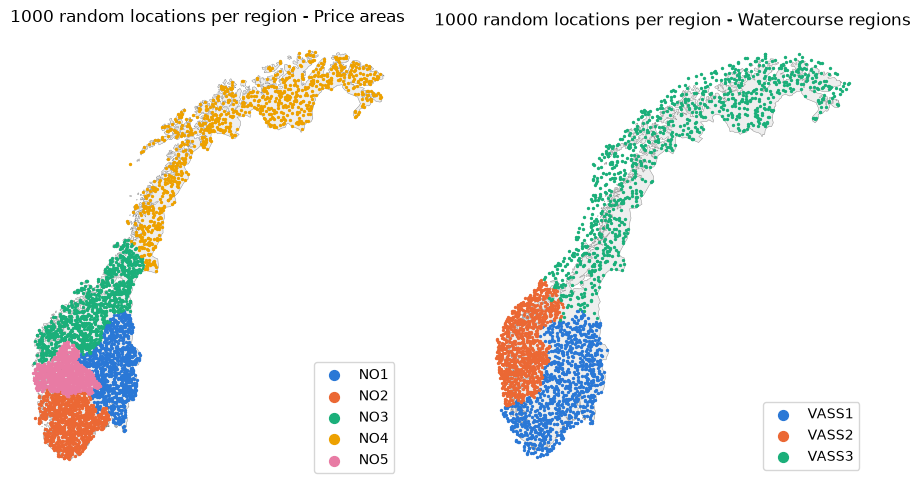

In [5]:
# The sampled locations: price areas to the left, watercourse regions to the right
fig, axes = plt.subplots(1, 2, figsize=(11, 7))
for ax, codes, title in [(axes[0], ["NO1", "NO2", "NO3", "NO4", "NO5"], "Price areas"),
                         (axes[1], ["VASS1", "VASS2", "VASS3"], "Watercourse regions")]:
    regions[regions["region"] == "NO"].plot(ax=ax, color="#eeeeee", edgecolor="grey", linewidth=0.3)
    for code, color in zip(codes, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]):
        lon, lat = zip(*locations[code])
        ax.scatter(lon, lat, s=2, color=color, label=code)
    ax.legend(markerscale=5, loc="lower right")
    ax.set_title(f"1000 random locations per region - {title}")
    ax.set_axis_off()
plt.show()

The locations are stored in MongoDB, so the Streamlit app can look them up without the shapefiles.

In [6]:
client = MongoClient(secrets["mongo"]["uri"])
client.admin.command("ping")
location_collection = client["ind320"]["region_locations"]

# One document per region with its list of [longitude, latitude] pairs
location_collection.delete_many({})
location_collection.insert_many([{"region": region, "locations": [list(p) for p in pairs]}
                                 for region, pairs in locations.items()])
print("Regions in MongoDB:", location_collection.distinct("region"))

Regions in MongoDB: ['NO', 'NO1', 'NO2', 'NO3', 'NO4', 'NO5', 'VASS1', 'VASS2', 'VASS3']


## 4. Weather data from open-meteo (ERA5)

open-meteo's [historical API](https://open-meteo.com/en/docs/historical-weather-api) gives hourly
reanalysis data. `models=era5` selects the ERA5 model. Several locations can be asked for in one request
(comma-separated latitudes and longitudes), and the answer is then a list with one result per location.

The free API limits the amount of data per day, so the function downloads a random subset of the
region's 1000 locations (`n_locations`, default 10; `n_locations=1` gives a single location). Times are
in UTC, so there are no daylight-saving jumps in the series.

In [7]:
ARCHIVE_API = "https://archive-api.open-meteo.com/v1/archive"
HOURLY_VARIABLES = ["temperature_2m", "precipitation", "rain", "snowfall", "relative_humidity_2m",
                    "wind_speed_10m", "wind_gusts_10m", "cloud_cover", "surface_pressure"]


def download_weather(region: str, start: str, end: str, n_locations: int = 10, seed: int = 1) -> pd.DataFrame:
    """Hourly ERA5 weather for random locations in a region, between start and end ("YYYY-MM-DD")."""
    pairs = locations[region]                                     # look up the region's locations
    rng = np.random.default_rng(seed)
    chosen = [pairs[i] for i in rng.choice(len(pairs), size=n_locations, replace=False)]

    params = {
        "latitude": ",".join(str(lat) for lon, lat in chosen),
        "longitude": ",".join(str(lon) for lon, lat in chosen),
        "start_date": start, "end_date": end,
        "hourly": ",".join(HOURLY_VARIABLES),
        "models": "era5", "timezone": "GMT",
    }
    response = requests.get(ARCHIVE_API, params=params, timeout=120)
    response.raise_for_status()
    results = response.json()
    if isinstance(results, dict):          # one location -> a dict, several -> a list
        results = [results]

    frames = []
    for i, (result, (lon, lat)) in enumerate(zip(results, chosen)):
        frame = pd.DataFrame(result["hourly"])
        frame["location"], frame["longitude"], frame["latitude"] = i, lon, lat
        frames.append(frame)
    weather = pd.concat(frames, ignore_index=True)
    weather["time"] = pd.to_datetime(weather["time"])
    return weather

In [8]:
# NO3 for 2024
no3_all = download_weather("NO3", "2024-01-01", "2024-12-31")
print("Rows (hours x locations):", len(no3_all), "| locations:", no3_all["location"].nunique())

# The region average per hour is used in the analysis below
no3 = no3_all.groupby("time")[HOURLY_VARIABLES].mean()
no3.describe().T[["mean", "min", "max"]].round(2)

Rows (hours x locations): 87840 | locations: 10


,mean,min,max
temperature_2m,3.37,-17.05,24.38
precipitation,0.22,0.00,3.32
rain,0.14,0.00,1.92
snowfall,0.05,0.00,1.76
relative_humidity_2m,79.38,28.20,96.90
wind_speed_10m,9.51,2.24,32.36
wind_gusts_10m,29.29,7.74,106.45
cloud_cover,78.75,0.00,100.00
surface_pressure,919.73,873.97,946.35


## 5. Outliers in precipitation (SPC with DCT)

1. The Discrete Cosine Transform (DCT) writes the series as a sum of cosines with increasing frequency.
   Setting the components below `freq_cutoff` to zero and transforming back is a high-pass filter. What
   is left are the seasonally adjusted variations (SATV, as the task calls them).
2. Robust statistics from the whole year: the median and the MAD of the SATV (MAD × 1.4826 is a
   standard deviation for normal data). These are not pulled by the extreme values themselves.
3. SPC limits = median ± `n_std` robust standard deviations. The limits are added to the slow part that
   was removed, so they follow the season in the plot. Hours outside are outliers. The SATV values
   themselves are not plotted.

In [9]:
def precipitation_spc(precip: pd.Series, freq_cutoff: float = 1 / 30, n_std: float = 3.0):
    """Precipitation plot with SPC limits and outliers.

    freq_cutoff: in cycles per day; slower variations are removed (1/30 -> about a month).
    n_std: number of robust standard deviations for the limits.
    Returns (figure, summary dict, table of outliers).
    """
    x = precip.to_numpy(dtype=float)
    n = len(x)
    step_days = (precip.index[1] - precip.index[0]) / pd.Timedelta(days=1)   # 1/24 for hourly data

    coeffs = dct(x, norm="ortho")
    freq = np.arange(n) / (2 * n * step_days)      # frequency of each DCT component (cycles per day)
    coeffs[freq < freq_cutoff] = 0                 # high-pass
    satv = idct(coeffs, norm="ortho")
    slow = x - satv                                # the slow part that was removed

    center = np.median(satv)
    sigma = 1.4826 * np.median(np.abs(satv - center))
    upper = slow + center + n_std * sigma
    lower = slow + center - n_std * sigma
    is_out = (satv > center + n_std * sigma) | (satv < center - n_std * sigma)

    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(precip.index, x, color=LINE, linewidth=0.6, label="Precipitation")
    ax.plot(precip.index, upper, color=LIMIT, linewidth=1.2, linestyle="--", label="Upper SPC limit")
    ax.plot(precip.index, lower, color=LIMIT, linewidth=1.2, linestyle=":", label="Lower SPC limit")
    ax.scatter(precip.index[is_out], x[is_out], color=OUTLIER, s=8, zorder=3, label="Outliers")
    ax.set_title(f"Precipitation with SPC limits (cut-off {freq_cutoff:.3f} per day, {n_std} std): "
                 f"{is_out.sum()} outliers")
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel("Precipitation (mm per hour)")
    ax.legend(loc="upper left", ncol=4, fontsize=9)
    plt.close(fig)   # returned, shown by the caller

    outliers = pd.DataFrame({"time": precip.index[is_out], "precipitation_mm": x[is_out],
                             "side": np.where(satv[is_out] > center, "above", "below")})
    summary = {"hours": n, "outliers": int(is_out.sum()), "share": round(float(is_out.mean()), 4),
               "above": int((satv > center + n_std * sigma).sum()),
               "below": int((satv < center - n_std * sigma).sum()),
               "robust_std_mm": round(float(sigma), 4),
               "largest_mm": round(float(x[is_out].max()), 2) if is_out.any() else None}
    return fig, summary, outliers

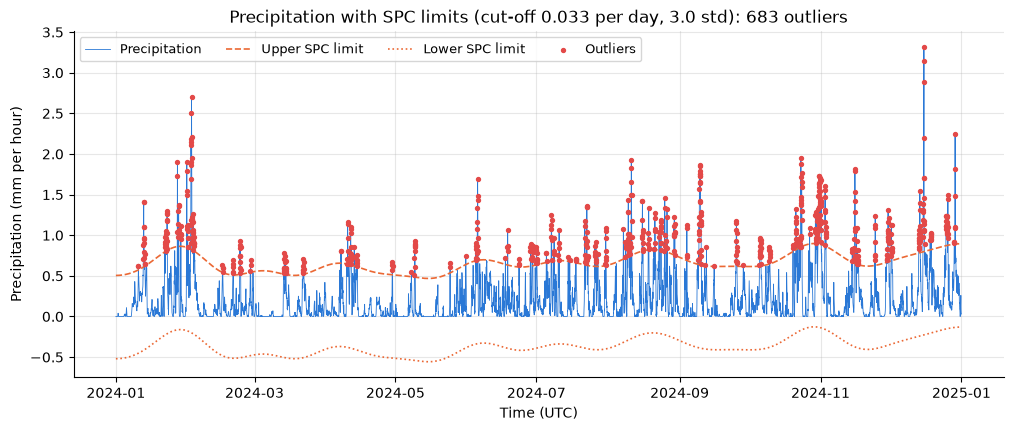

{'hours': 8784, 'outliers': 683, 'share': 0.0778, 'above': 683, 'below': 0, 'robust_std_mm': 0.1709, 'largest_mm': 3.32}


,time,precipitation_mm,side
639,2024-12-15 18:00:00,3.32,above
640,2024-12-15 19:00:00,3.14,above
638,2024-12-15 17:00:00,2.88,above
70,2024-02-02 18:00:00,2.70,above
69,2024-02-02 17:00:00,2.50,above


In [10]:
# Test with the default settings
fig, summary, outliers = precipitation_spc(no3["precipitation"])
display(fig)
print(summary)
outliers.sort_values("precipitation_mm", ascending=False).head(5)

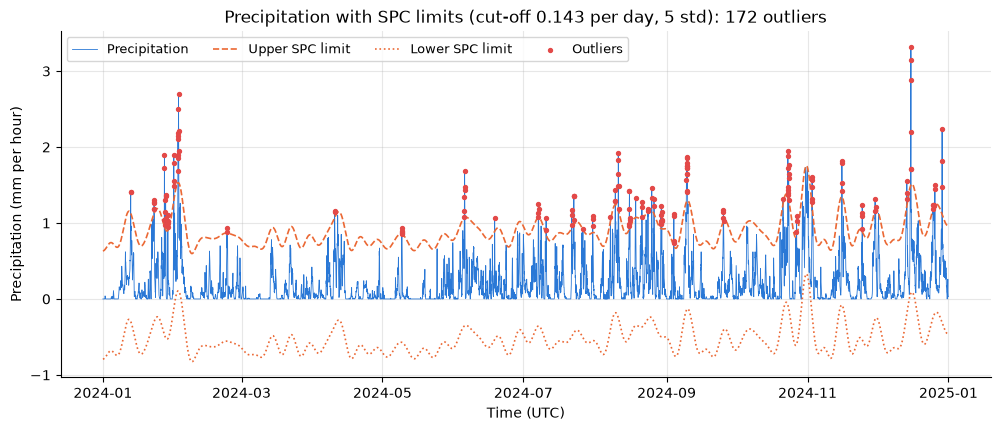

{'hours': 8784, 'outliers': 172, 'share': 0.0196, 'above': 172, 'below': 0, 'robust_std_mm': 0.1424, 'largest_mm': 3.32}


In [11]:
# Test with other settings: shorter cut-off (1 week) and wider limits (5 std) -> fewer outliers
fig, summary, outliers = precipitation_spc(no3["precipitation"], freq_cutoff=1 / 7, n_std=5)
display(fig)
print(summary)

Precipitation is zero or small most of the time and comes in short heavy bursts, so almost all outliers
are *above* the upper limit, and with 3 standard deviations the share of outliers (about 7-8%) is much
higher than the 0.3% expected for normally distributed data.

## 6. Anomalies in temperature (Local Outlier Factor)

LOF compares the density around each point with the density around its `n_neighbors` nearest
neighbours. Points in much sparser areas than their neighbours get a high score. `contamination` is the
proportion of points that are marked as outliers (default 1%).

LOF is applied to the deviation from a 30-day moving average, so an anomaly is an hour that is
unusually warm or cold *for the time of year*. With the default of 20 neighbours, LOF also marked
ordinary temperatures that happened to lie in small gaps between nearby values (8784 hours is a lot of
points), so 100 neighbours is used as the default.

In [12]:
def temperature_lof(temp: pd.Series, contamination: float = 0.01, n_neighbors: int = 100,
                    window_days: int = 30):
    """Temperature plot with LOF anomalies. Returns (figure, summary dict, table of anomalies).

    LOF is run on the deviation from a moving average over window_days (unusual for the season).
    """
    x = temp.to_numpy(dtype=float)
    seasonal = temp.rolling(f"{window_days}D", center=True, min_periods=1).mean().to_numpy()
    deviation = x - seasonal
    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)
    is_out = lof.fit_predict(deviation.reshape(-1, 1)) == -1   # -1 = outlier
    scores = -lof.negative_outlier_factor_                     # higher = more unusual

    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(temp.index, x, color=LINE, linewidth=0.6, label="Temperature")
    ax.plot(temp.index, seasonal, color="grey", linewidth=1.2, label=f"{window_days}-day mean")
    ax.scatter(temp.index[is_out], x[is_out], color=OUTLIER, s=10, zorder=3, label="Anomalies (LOF)")
    ax.set_title(f"Temperature with LOF anomalies (proportion {contamination:.1%}): {is_out.sum()} anomalies")
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel("Temperature (°C)")
    ax.legend(loc="upper left")
    plt.close(fig)

    anomalies = pd.DataFrame({"time": temp.index[is_out], "temperature_C": x[is_out],
                              "deviation_C": deviation[is_out].round(1), "lof_score": scores[is_out]})
    summary = {"hours": len(x), "anomalies": int(is_out.sum()), "share": round(float(is_out.mean()), 4),
               "warmer_than_usual": int((deviation[is_out] > 0).sum()),
               "colder_than_usual": int((deviation[is_out] < 0).sum()),
               "largest_deviation_C": round(float(np.abs(deviation[is_out]).max()), 1) if is_out.any() else None}
    return fig, summary, anomalies.sort_values("lof_score", ascending=False)

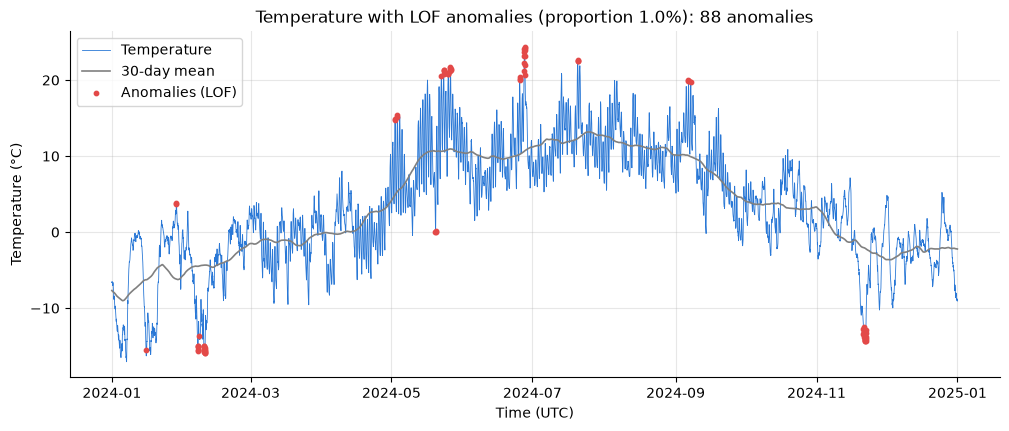

{'hours': 8784, 'anomalies': 88, 'share': 0.01, 'warmer_than_usual': 40, 'colder_than_usual': 48, 'largest_deviation_C': 13.7}


,time,temperature_C,deviation_C,lof_score
52,2024-06-27 16:00:00,24.38,13.7,4.187806
51,2024-06-27 15:00:00,24.19,13.5,4.023982
50,2024-06-27 14:00:00,24.08,13.4,3.933833
53,2024-06-27 17:00:00,23.98,13.3,3.807867
49,2024-06-27 13:00:00,23.64,13.0,3.539594


In [13]:
# Test with the default 1%
fig, summary, anomalies = temperature_lof(no3["temperature_2m"])
display(fig)
print(summary)
anomalies.head(5)

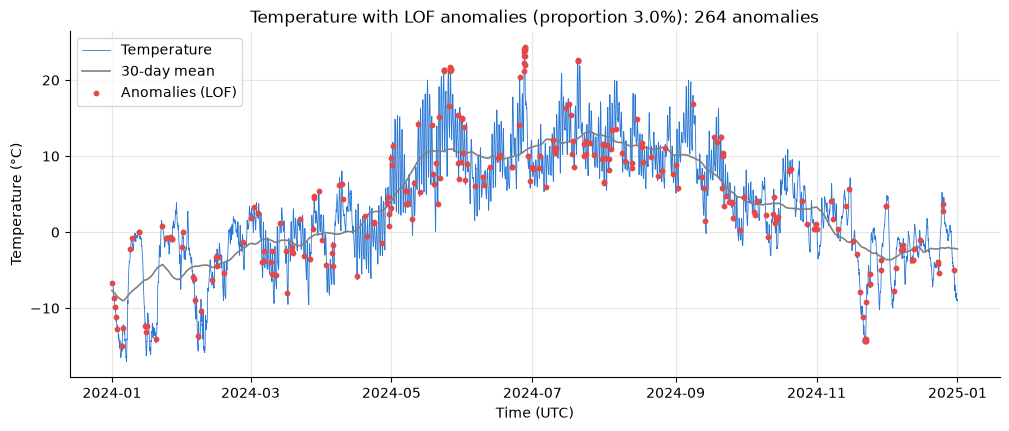

{'hours': 8784, 'anomalies': 264, 'share': 0.0301, 'warmer_than_usual': 98, 'colder_than_usual': 166, 'largest_deviation_C': 13.7}


In [14]:
# Test with 3% anomalies and only 20 neighbours (then ordinary values are marked too)
fig, summary, anomalies = temperature_lof(no3["temperature_2m"], contamination=0.03, n_neighbors=20)
display(fig)
print(summary)

With the defaults the anomalies are the hours that are furthest from the 30-day mean, for example the
heat at the end of June and the cold spells in January and November. With 20 neighbours (second test),
many ordinary hours are marked as well.

## 7. STL decomposition of the reservoir filling

The filling ratio is downloaded from the Magasinstatistikk API (as in part 2). The data is weekly, so
the period is 52. STL (Seasonal-Trend decomposition using LOESS) splits the series into a trend, a
seasonal pattern and a residual.

- `seasonal`: length of the seasonal smoother (odd). Small values let the seasonal pattern change faster.
- `trend`: length of the trend smoother (odd, longer than the period). 89 weeks is statsmodels' rule of
  thumb for period 52 and seasonal 13.
- `robust`: down-weights unusual weeks so they do not pull the trend and season.

In [15]:
# Weekly reservoir data from the NVE API, with the same renaming as before
NVE_API = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"
reservoirs = pd.DataFrame(requests.get(f"{NVE_API}/HentOffentligData", timeout=60).json())
reservoirs = reservoirs.rename(columns={"dato_Id": "date", "omrType": "area_type", "omrnr": "area_number",
                                        "fyllingsgrad": "filling_ratio"})
reservoirs["date"] = pd.to_datetime(reservoirs["date"])
reservoirs = reservoirs.sort_values(["area_type", "area_number", "date"])   # the API is not sorted


def weekly_series(area_type: str = "NO", area_number: int = 0) -> pd.Series:
    """Filling ratio for one area as a regular weekly series (the dates are Sundays)."""
    area = reservoirs[(reservoirs["area_type"] == area_type) & (reservoirs["area_number"] == area_number)]
    return area.set_index("date")["filling_ratio"].asfreq("W-SUN").interpolate()


print(weekly_series().tail())

date
2026-10-04    0.678859
2026-10-11    0.689574
2026-10-18    0.692585
2026-10-25    0.695430
2026-11-01    0.713436
Freq: W-SUN, Name: filling_ratio, dtype: float64


In [16]:
def stl_plot(area_type: str = "NO", area_number: int = 0, seasonal: int = 13, trend: int = 89,
             robust: bool = True, period: int = 52):
    """STL decomposition of the filling ratio for one area. Returns the figure."""
    series = weekly_series(area_type, area_number)
    result = STL(series, period=period, seasonal=seasonal, trend=trend, robust=robust).fit()

    fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
    for ax, (name, values) in zip(axes, [("Observed", series), ("Trend", result.trend),
                                         ("Seasonal", result.seasonal), ("Residual", result.resid)]):
        ax.plot(values.index, values, color=LINE, linewidth=1)
        ax.set_ylabel(name)
    axes[0].set_title(f"STL of the filling ratio, {area_type} {area_number} "
                      f"(seasonal={seasonal}, trend={trend}, robust={robust})")
    axes[-1].set_xlabel("Date")
    plt.close(fig)
    return fig

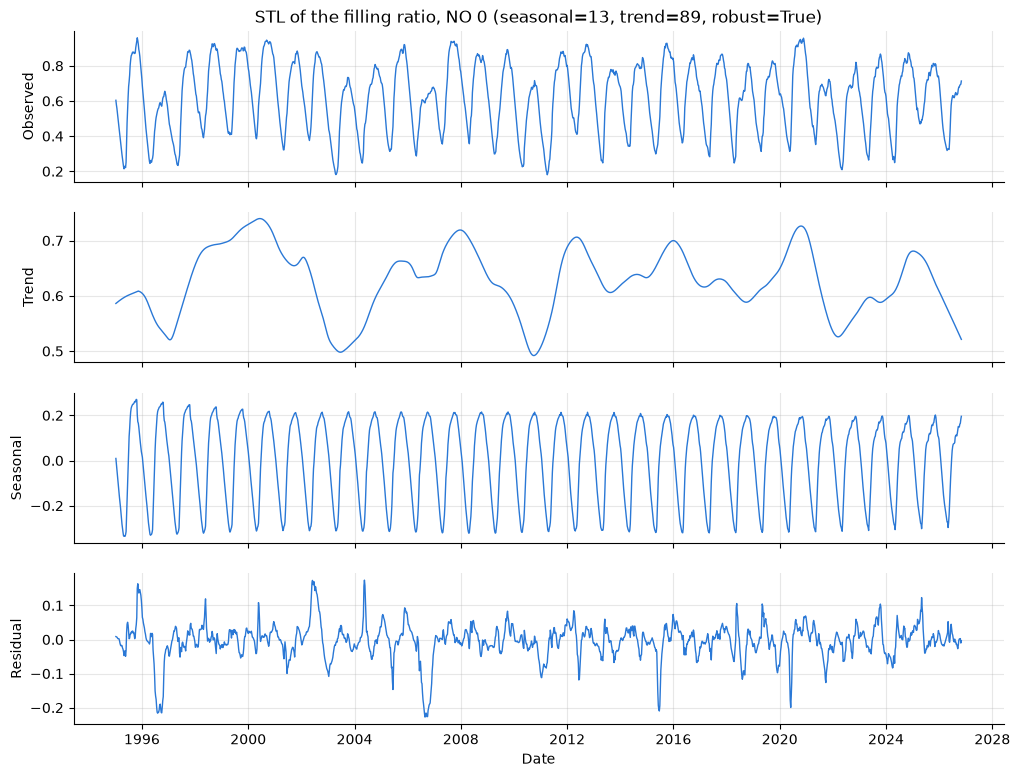

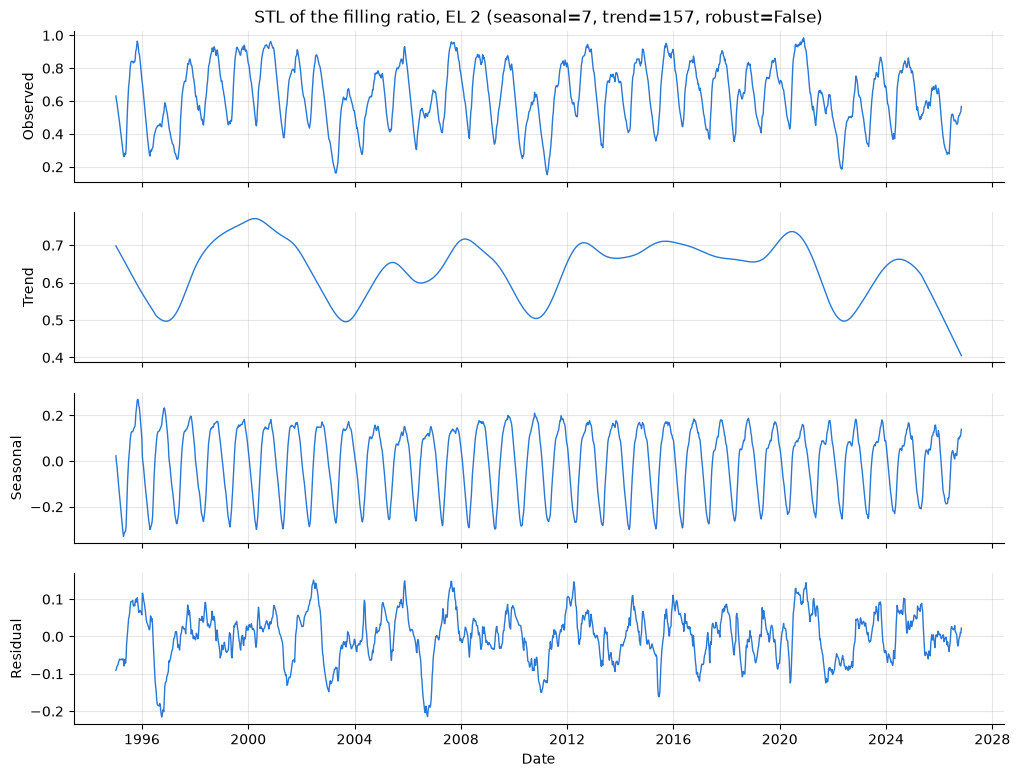

In [17]:
# Test: whole country with the defaults, and price area NO2 with a faster season and a smoother trend
display(stl_plot())
display(stl_plot("EL", 2, seasonal=7, trend=157, robust=False))

## 8. Spectrogram of the reservoir filling

The spectrogram cuts the series into overlapping windows and shows the power of each frequency in each
window. With 52 samples per year, the frequencies are in cycles per year, so the yearly cycle is at 1.

- `window_length`: weeks per window (default 104 = two years). Longer windows give finer frequency
  resolution but coarser time resolution.
- `overlap`: weeks shared by two neighbouring windows (default 78 = 75%).

In [18]:
def spectrogram_plot(area_type: str = "NO", area_number: int = 0, window_length: int = 104,
                     overlap: int = 78, max_freq: float = 6):
    """Spectrogram of the filling ratio for one area. Returns the figure."""
    series = weekly_series(area_type, area_number)
    f, t, power = spectrogram(series.to_numpy(), fs=52, nperseg=window_length, noverlap=overlap,
                              detrend="linear", scaling="density")
    times = series.index[0] + pd.to_timedelta(t * 365.25, unit="D")   # middle of each window

    fig, ax = plt.subplots(figsize=(12, 4.5))
    mesh = ax.pcolormesh(times, f, 10 * np.log10(power + 1e-12), shading="auto", cmap="viridis")
    fig.colorbar(mesh, ax=ax, label="Power (dB)")
    ax.set_ylim(0, max_freq)
    ax.set_title(f"Spectrogram of the filling ratio, {area_type} {area_number} "
                 f"(window {window_length} weeks, overlap {overlap} weeks)")
    ax.set_xlabel("Date (middle of window)")
    ax.set_ylabel("Frequency (cycles per year)")
    ax.grid(False)
    plt.close(fig)
    return fig

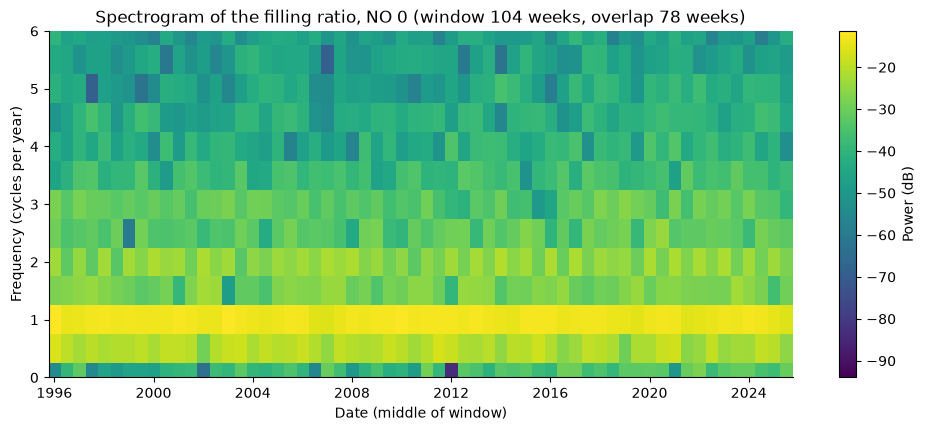

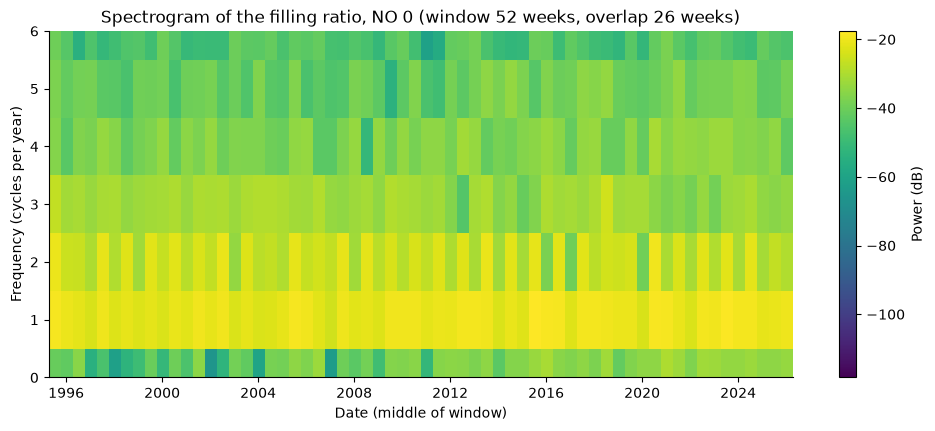

In [19]:
# Test: defaults, and a shorter window with less overlap
display(spectrogram_plot())
display(spectrogram_plot(window_length=52, overlap=26))

The strongest band is at 1 cycle per year (the yearly filling and emptying of the reservoirs), with
weaker harmonics at 2 and 3 cycles per year because the yearly cycle is not a pure sine wave.

In [20]:
client.close()